# Assignment 9: Preprocessing and Data Visualization

**Dataset:** UCI Automobile (Jeffrey Schlimmer, 1985), 205 cars and 26 columns, from
https://archive.ics.uci.edu/dataset/10/automobile.

- `imports-85.data` is the data itself. It has no header row.
- `imports-85.names` is UCI's documentation: the column names, the range each numeric column
  spans, and how many values are missing.

Both files are used exactly as downloaded.

In [1]:
"""Assignment 9: preprocess, visualize and test the UCI Automobile dataset."""
import re
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# ---- file locations (all in the same folder as this notebook) ----
DATA_FILE = Path("imports-85.data")
NAMES_FILE = Path("imports-85.names")
CLEAN_FILE = Path("automobile_clean.csv")

# Show every column and the full text of each note when printing tables.
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

## Question 1: Preprocessing

> Select one of the following three datasets and perform the preprocessing steps we addressed
> in class on at least one column. For those preprocessing steps we did not cover, provide a
> one-sentence definition in your own words.

**My preprocessing design.** Every step on the slide-6 list from Lecture 9 is covered:

| Slide 6 step | What I do | Column(s) |
|---|---|---|
| 1. Cleaning up null values | Turn the file's `?` marker into a real null | 7 columns |
| 2. Data cleaning | Column names in snake_case; all text lowercase and trimmed; numbers stored as text converted to numbers; two misspelled makes fixed; `make` in Title Case, with BMW kept all caps | all |
| 2.1 Handle missing data | Drop the 4 cars with no price, because Q3 measures price and a guessed price would be invented data. Leave the other gaps as null, because nothing later uses those columns | `price` |
| 2.2 Remove extreme outliers | Exclude values outside the ranges in UCI's documentation, which would be storage errors. Flag statistical extremes (beyond 3 IQRs) for review, and keep the ones that are real cars | 16 numeric columns |
| 3. One-hot encoding | 0/1 columns with the first category dropped, keeping the original label columns | `fuel_type`, `aspiration`, `drive_wheels`, `body_style` |
| 4. Convert categorical values to numerical | The one-hot columns are this conversion. `num_of_cylinders` and `num_of_doors` stay as nominal text by choice | same as step 3 |
| 5. Standardization/normalization | `price_z`: each price in standard deviations from the mean | `price` |
| 6. Deal with multicollinearity | One-hot drops one column per category (the dummy-variable trap), and `highway_mpg` is dropped because it nearly duplicates `city_mpg` | dummies, `highway_mpg` |

In [2]:
# ---- preprocessing decisions ----
MISSING_MARKER = "?"                     # how the file marks a missing value
MAKE_SPELLING_FIXES = {"alfa-romero": "alfa-romeo", "peugot": "peugeot"}
MAKE_CASE_EXCEPTIONS = {"bmw": "BMW"}    # .title() would give "Bmw"
ONE_HOT_COLUMNS = ["fuel_type", "aspiration", "drive_wheels", "body_style"]
OUTLIER_FENCE_IQRS = 3.0                 # Tukey's "extreme" fence: 3 IQRs past the quartiles
COLLINEARITY_CUTOFF = 0.9                # |r| at or above this counts as a near-duplicate
COLLINEAR_DROP = "highway_mpg"           # keep city_mpg, drop its near-duplicate

In [3]:
def read_documentation(names_file: Path) -> tuple[list[str], dict[str, tuple[float, float]]]:
    """Read the column names and documented numeric ranges from UCI's names file.

    Section 7 of the file lists each column as "N. name: range". Numeric columns say
    "continuous from LOW to HIGH" (one line leaves out the "to"), and symboling lists
    its allowed values, -3 to 3.

    Args:
        names_file: Path to imports-85.names.

    Returns:
        The 26 column names in snake_case, and {column: (low, high)} for each numeric column.
    """
    text = names_file.read_text(encoding="utf-8")
    section = text.split("7. Attribute Information:")[1].split("8. Missing")[0]
    number = r"(\d+(?:\.\d+)?)"   # a number; stops before a sentence-ending period
    columns, ranges = [], {}
    for name, spec in re.findall(r"^\s*\d+\.\s+([a-z0-9-]+):\s+(.*)$", section, re.MULTILINE):
        column = name.replace("-", "_")          # snake_case: num-of-doors -> num_of_doors
        columns.append(column)
        bounds = re.search(rf"continuous from {number}(?: to)? {number}", spec)
        if bounds:
            ranges[column] = (float(bounds.group(1)), float(bounds.group(2)))
        elif column == "symboling":
            allowed = [int(value) for value in re.findall(r"-?\d+", spec)]
            ranges[column] = (min(allowed), max(allowed))
    return columns, ranges


def load_raw(data_file: Path, columns: list[str]) -> pd.DataFrame:
    """Load the data exactly as stored: every value kept as text, nothing turned into null yet.

    Args:
        data_file: Path to imports-85.data (no header row).
        columns: Column names to give the 26 columns.

    Returns:
        The raw table, all text.
    """
    return pd.read_csv(data_file, header=None, names=columns, dtype=str, keep_default_na=False)

In [4]:
def standardize_text(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Trim spaces from every text value and make it lowercase.

    Args:
        frame: The raw table (every column is text at this point).

    Returns:
        The cleaned table, and a note saying how many values changed.
    """
    cleaned = frame.apply(lambda column: column.str.strip().str.lower())
    changed = int((cleaned != frame).sum().sum())
    return cleaned, f"{changed} values changed (the file was already lowercase and trimmed)"


def mark_missing(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Turn the file's missing-value marker, "?", into a real null.

    Args:
        frame: The table, still all text.

    Returns:
        The table with nulls, and a note listing how many "?" each column had.
    """
    is_missing = frame == MISSING_MARKER
    counts = is_missing.sum()
    found = ", ".join(f"{column} {count}" for column, count in counts[counts > 0].items())
    return frame.mask(is_missing), f"? to null: {found}"


def convert_types(frame: pd.DataFrame, numeric_columns: list[str]) -> tuple[pd.DataFrame, str]:
    """Turn the numeric columns from text into numbers.

    Whole-number columns become pandas' nullable Int64, which can hold a missing value
    (a plain int column can't). Columns with decimals become floats.

    Args:
        frame: The table with nulls in place.
        numeric_columns: The columns UCI documents as numeric.

    Returns:
        The table with real numbers, and a note naming the integer and decimal columns.
    """
    converted = frame.copy()
    whole, decimal = [], []
    for column in numeric_columns:
        values = pd.to_numeric(converted[column])      # raises if any value isn't a number
        if values.dropna().mod(1).eq(0).all():
            converted[column] = values.astype("Int64")
            whole.append(column)
        else:
            converted[column] = values
            decimal.append(column)
    return converted, f"text to Int64: {', '.join(whole)}; text to float: {', '.join(decimal)}"


def clean_make(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Fix the misspelled makes, then put make in Title Case (BMW stays all caps).

    Args:
        frame: The table with lowercase text.

    Returns:
        The table with clean makes, and a note on how many rows were respelled.
    """
    cleaned = frame.copy()
    respelled = cleaned["make"].replace(MAKE_SPELLING_FIXES)
    fixed = int((respelled != cleaned["make"]).sum())
    cleaned["make"] = respelled.map(lambda make: MAKE_CASE_EXCEPTIONS.get(make, make.title()))
    pairs = ", ".join(f"{old} to {new}" for old, new in MAKE_SPELLING_FIXES.items())
    return cleaned, f"{fixed} rows respelled ({pairs}); make in Title Case"

In [5]:
def drop_missing_price(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Drop the cars with no price, and leave every other gap as null.

    Q3 measures price, so a filled-in price would be invented data. The other gaps are in
    columns nothing later depends on, so they stay null rather than being guessed.

    Args:
        frame: The typed table.

    Returns:
        The table without the unpriced cars, and a note listing the gaps left as null.
    """
    has_price = frame["price"].notna()
    kept = frame[has_price].copy()
    kept["price"] = kept["price"].astype("int64")   # no gaps left, so a plain int works
    gaps = kept.isna().sum()
    left = ", ".join(f"{column} {count}" for column, count in gaps[gaps > 0].items())
    return kept, f"dropped {int((~has_price).sum())} cars with no price; left as null: {left}"


def remove_storage_errors(frame: pd.DataFrame,
                          ranges: dict[str, tuple[float, float]]) -> tuple[pd.DataFrame, str]:
    """Remove rows holding a value outside the range UCI documents for its column.

    A value outside its documented range can't be a real reading from this dataset, so it
    points to a storage error. Missing values are not errors here.

    Args:
        frame: The table after missing data is handled.
        ranges: {column: (low, high)} from the documentation.

    Returns:
        The table without error rows, and a note saying how many were removed.
    """
    error_rows = pd.Series(False, index=frame.index)
    for column, (low, high) in ranges.items():
        outside = ((frame[column] < low) | (frame[column] > high)).fillna(False)
        error_rows |= outside.astype(bool)
    removed = int(error_rows.sum())
    return frame[~error_rows].copy(), f"{removed} rows outside documented ranges removed"


def flag_extreme_outliers(frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """List the values beyond Tukey's extreme fence, so each one can be reviewed.

    The fence sits 3 interquartile ranges (IQRs) below the first quartile and above the
    third. A flagged value is unusual, not necessarily wrong, so this only reports.

    Args:
        frame: The table after storage errors are removed.
        columns: The numeric columns to check.

    Returns:
        One row per flagged value: the column, the fence, the value and which car it is.
    """
    flagged = []
    for column in columns:
        q1, q3 = frame[column].quantile([0.25, 0.75])
        reach = OUTLIER_FENCE_IQRS * (q3 - q1)
        low, high = q1 - reach, q3 + reach
        outside = ((frame[column] < low) | (frame[column] > high)).fillna(False).astype(bool)
        for _, car in frame[outside].iterrows():
            flagged.append({"column": column, "fence": f"{low:g} to {high:g}",
                            "value": car[column], "make": car["make"],
                            "fuel_type": car["fuel_type"]})
    return pd.DataFrame(flagged)

In [6]:
def one_hot_encode(frame: pd.DataFrame, columns: list[str]) -> tuple[pd.DataFrame, str]:
    """Add a 0/1 column per category, dropping the first category of each column.

    Dropping one avoids the dummy-variable trap: a full set of 0/1 columns always adds up
    to 1, so any one of them can be predicted from the others. The dropped category is the
    baseline (all zeros). The original label columns stay for the charts and the ANOVA.

    Args:
        frame: The table after outliers are handled.
        columns: The nominal columns to encode.

    Returns:
        The table with the new 0/1 columns added, and a note listing them.
    """
    dummies = pd.get_dummies(frame[columns], drop_first=True, dtype=int)
    return pd.concat([frame, dummies], axis=1), f"added {', '.join(dummies.columns)}"


def add_price_zscore(frame: pd.DataFrame) -> tuple[pd.DataFrame, str]:
    """Add price_z: each price as the number of standard deviations from the mean price.

    Args:
        frame: The table with price as a plain integer.

    Returns:
        The table with price_z added, and a note with the mean and standard deviation used.
    """
    standardized = frame.copy()
    mean, std = standardized["price"].mean(), standardized["price"].std()
    standardized["price_z"] = (standardized["price"] - mean) / std
    return standardized, f"price_z = (price - {mean:,.0f}) / {std:,.0f}"


def find_collinear_pairs(frame: pd.DataFrame, columns: list[str],
                         cutoff: float) -> list[tuple[str, str, float]]:
    """Find pairs of numeric columns whose correlation is at or above the cutoff.

    Args:
        frame: The table to check.
        columns: The numeric columns to compare.
        cutoff: The absolute correlation that counts as a near-duplicate.

    Returns:
        (first column, second column, |r|) for each pair at or above the cutoff.
    """
    strength = frame[columns].astype(float).corr().abs()
    pairs = []
    for position, first in enumerate(columns):
        for second in columns[position + 1:]:
            if strength.loc[first, second] >= cutoff:
                pairs.append((first, second, round(float(strength.loc[first, second]), 3)))
    return pairs


def drop_collinear(frame: pd.DataFrame, columns: list[str]) -> tuple[pd.DataFrame, str]:
    """Drop COLLINEAR_DROP, after confirming it is part of a near-duplicate pair.

    Args:
        frame: The table to check.
        columns: The numeric columns to compare.

    Returns:
        The table without the dropped column, and a note listing every pair found.

    Raises:
        ValueError: If COLLINEAR_DROP isn't in any pair, so the drop would be unjustified.
    """
    pairs = find_collinear_pairs(frame, columns, COLLINEARITY_CUTOFF)
    if not any(COLLINEAR_DROP in pair[:2] for pair in pairs):
        raise ValueError(f"{COLLINEAR_DROP} is not in any pair with |r| >= {COLLINEARITY_CUTOFF}")
    found = "; ".join(f"{first} and {second}, r = {r}" for first, second, r in pairs)
    return frame.drop(columns=COLLINEAR_DROP), f"pairs with |r| >= {COLLINEARITY_CUTOFF}: {found}"

In [7]:
def preprocess(data_file: Path, names_file: Path) -> tuple[pd.DataFrame, pd.DataFrame, list[str]]:
    """Run every Question 1 step in order and log what each one did.

    Args:
        data_file: Path to imports-85.data.
        names_file: Path to imports-85.names.

    Returns:
        The clean table, a log with one row per step, and the numeric column names.
    """
    columns, ranges = read_documentation(names_file)
    frame = load_raw(data_file, columns)
    log = [{"step": "Load, column names from the documentation, in snake_case",
            "slide 6": "2. Data cleaning", "rows": frame.shape[0], "columns": frame.shape[1],
            "what changed": f"{len(columns)} columns named; {len(ranges)} documented as numeric"}]
    numeric = list(ranges)
    steps = [
        ("Lowercase and trim all text", "2. Data cleaning", standardize_text),
        ("? to null", "1. Cleaning up null values", mark_missing),
        ("Numbers stored as text to numbers", "2. Data cleaning",
         partial(convert_types, numeric_columns=numeric)),
        ("Fix misspelled makes, Title Case", "2. Data cleaning", clean_make),
        ("Drop cars with no price", "2.1 Handle missing data", drop_missing_price),
        ("Remove storage errors", "2.2 Remove extreme outliers",
         partial(remove_storage_errors, ranges=ranges)),
        ("One-hot encode, first category dropped", "3. One-hot / 4. Categorical to numerical",
         partial(one_hot_encode, columns=ONE_HOT_COLUMNS)),
        ("Standardize price", "5. Standardization", add_price_zscore),
        ("Drop highway_mpg", "6. Multicollinearity", partial(drop_collinear, columns=numeric)),
    ]
    for name, slide_item, step in steps:
        frame, note = step(frame)
        log.append({"step": name, "slide 6": slide_item, "rows": frame.shape[0],
                    "columns": frame.shape[1], "what changed": note})
    numeric = [column for column in numeric if column in frame.columns]
    return frame, pd.DataFrame(log), numeric


def print_log(log: pd.DataFrame) -> None:
    """Print the step log one step per block, so the long notes stay readable.

    Args:
        log: The log from preprocess().
    """
    for number, entry in enumerate(log.itertuples(index=False), start=1):
        print(f"{number}. {entry.step}  [slide 6: {entry[1]}]  "
              f"-> {entry.rows} rows x {entry.columns} columns")
        print(f"   {entry[4]}")

### Running the preprocessing

Each row of the log is one step: how many rows and columns the table has afterwards, and what
the step changed.

In [8]:
CLEAN, STEP_LOG, NUMERIC_COLUMNS = preprocess(DATA_FILE, NAMES_FILE)
print_log(STEP_LOG)

1. Load, column names from the documentation, in snake_case  [slide 6: 2. Data cleaning]  -> 205 rows x 26 columns
   26 columns named; 16 documented as numeric
2. Lowercase and trim all text  [slide 6: 2. Data cleaning]  -> 205 rows x 26 columns
   0 values changed (the file was already lowercase and trimmed)
3. ? to null  [slide 6: 1. Cleaning up null values]  -> 205 rows x 26 columns
   ? to null: normalized_losses 41, num_of_doors 2, bore 4, stroke 4, horsepower 2, peak_rpm 2, price 4
4. Numbers stored as text to numbers  [slide 6: 2. Data cleaning]  -> 205 rows x 26 columns
   text to Int64: symboling, normalized_losses, curb_weight, engine_size, horsepower, peak_rpm, city_mpg, highway_mpg, price; text to float: wheel_base, length, width, height, bore, stroke, compression_ratio
5. Fix misspelled makes, Title Case  [slide 6: 2. Data cleaning]  -> 205 rows x 26 columns
   14 rows respelled (alfa-romero to alfa-romeo, peugot to peugeot); make in Title Case
6. Drop cars with no price 

### Before and after

The same five cars, as stored in the file and after cleaning. They include the misspelled
`alfa-romero` and `peugot`, `bmw`, a car with `?` for horsepower, and a car with no price.

In [9]:
RAW = load_raw(DATA_FILE, read_documentation(NAMES_FILE)[0])
SHOWN = ["make", "num_of_doors", "horsepower", "price"]
EXAMPLES = [0, 9, 11, 107, 130]           # rows in the original file
print("As stored:")
print(RAW.loc[EXAMPLES, SHOWN].to_string())
print("\nAfter cleaning (row 9 has no price, so it was dropped):")
print(CLEAN.loc[CLEAN.index.intersection(EXAMPLES), SHOWN + ["price_z"]].round(3).to_string())
print("\nTypes after cleaning:")
print(CLEAN[["make", "num_of_doors", "horsepower", "bore", "price", "price_z"]].dtypes.to_string())

As stored:
            make num_of_doors horsepower  price
0    alfa-romero          two        111  13495
9           audi          two        160      ?
11           bmw         four        101  16925
107       peugot         four         97  11900
130      renault         four          ?   9295

After cleaning (row 9 has no price, so it was dropped):
           make num_of_doors  horsepower  price  price_z
0    Alfa-Romeo          two         111  13495    0.036
11          BMW         four         101  16925    0.468
107     Peugeot         four          97  11900   -0.164
130     Renault         four        <NA>   9295   -0.492

Types after cleaning:
make                str
num_of_doors        str
horsepower        Int64
bore            float64
price             int64
price_z         float64


### Proving the range check works

The documented ranges were written from this same data, so the real file passes by design. The
check still guards against a value damaged later, for example a typo while editing. To show it
catches one, a copy of the clean data gets one planted error: an extra digit in a horsepower.

In [10]:
PLANTED = CLEAN.copy()
PLANTED.loc[PLANTED.index[0], "horsepower"] = 1110          # the real value is 111
DOCUMENTED = {column: bounds for column, bounds in read_documentation(NAMES_FILE)[1].items()
              if column in PLANTED.columns}                  # highway_mpg was dropped
CAUGHT, CAUGHT_NOTE = remove_storage_errors(PLANTED, DOCUMENTED)
print(f"Documented horsepower range: {DOCUMENTED['horsepower']}")
print(f"With horsepower 1110 planted: {CAUGHT_NOTE}; {len(CAUGHT)} of {len(PLANTED)} rows kept")

Documented horsepower range: (48.0, 288.0)
With horsepower 1110 planted: 1 rows outside documented ranges removed; 200 of 201 rows kept


### Reviewing the extreme values

**Why I check statistically:** I think people should make informed decisions on how to handle
outliers, which means that outliers have to be statistically determined in the first place. It's
not enough to just be like "ehhhh, that feels like an outlier", because depending on what
analysis you're doing, or what part of the story you're telling, you might want to handle
outliers differently, but first you have to know if they actually are there or not.

The documented-range check removed nothing, so no value is stored wrong. The 3-IQR fence
still flags these values as statistical extremes:

In [11]:
EXTREMES = flag_extreme_outliers(CLEAN, NUMERIC_COLUMNS)
print(EXTREMES.to_string(index=False))
print("\nFlagged per column:", EXTREMES["column"].value_counts().to_dict())

           column           fence    value          make fuel_type
      engine_size      -31 to 270   326.00        Jaguar       gas
      engine_size      -31 to 270   308.00 Mercedes-Benz       gas
      engine_size      -31 to 270   304.00 Mercedes-Benz       gas
           stroke    2.21 to 4.31     2.19       Peugeot       gas
           stroke    2.21 to 4.31     2.19       Peugeot       gas
           stroke    2.21 to 4.31     2.07          Saab       gas
compression_ratio     6.2 to 11.8    22.70         Mazda    diesel
compression_ratio     6.2 to 11.8    22.00         Mazda    diesel
compression_ratio     6.2 to 11.8    21.50 Mercedes-Benz    diesel
compression_ratio     6.2 to 11.8    21.50 Mercedes-Benz    diesel
compression_ratio     6.2 to 11.8    21.50 Mercedes-Benz    diesel
compression_ratio     6.2 to 11.8    21.50 Mercedes-Benz    diesel
compression_ratio     6.2 to 11.8    21.90        Nissan    diesel
compression_ratio     6.2 to 11.8    21.00       Peugeot    di

Every flagged value is a real car, so none are removed:

- **Compression ratio:** every flagged car runs on diesel, and diesel engines compress their
  air far more than gasoline engines do. That gives two separate clusters, not errors.
- **Engine size, horsepower and price:** Jaguar and Mercedes-Benz luxury cars. (The
  288-horsepower Porsche would have been flagged too, but it is one of the 4 cars with no
  price, so it was already dropped.)
- **Stroke:** a few short-stroke Peugeot and Saab engines.

Removing them would make the data look tidier and less true.

### Saving the clean data

The clean table is saved for Questions 2 and 3.

In [12]:
CLEAN.to_csv(CLEAN_FILE, index=False)
print(f"Saved {CLEAN_FILE}: {CLEAN.shape[0]} rows, {CLEAN.shape[1]} columns")

Saved automobile_clean.csv: 201 rows, 34 columns


### Definitions for the steps beyond the slide-6 list

- **Type conversion** is changing how a value is stored, like turning the text "13495" into the
  number 13495; I personally prefer numbers (ints or floats) to strings for ordinal and ratio
  data, because it lets you do math on them and they're cheaper to store, while it matters less
  for nominal data.
- **Text standardization** means writing the same value the same way every time; I strip leading
  and trailing spaces because spacing errors jump out at me instantly, and I use lowercase
  because I don't like data shouting at me (make is the one exception, in Title Case for
  display).
- **Snake_case** means lowercase words joined by underscores, like num_of_doors; I like
  lowercase_snake_case best because names with spaces need "quotes" in SQL and in data work
  generally.
- **Range validation** is a way to identify if a certain datapoint is even possible, by checking
  it against the range it's allowed to fall in, before deciding statistically whether it's an
  outlier.

## Question 2: Visualization

> Select 3-5 appropriate visuals to paint a picture of the data. Write a short summary of each in
> your own words and what it tells about the data you selected.

**The story: origin.** Every chart is colored by where the car's brand comes from: American,
European or Japanese. One twist first: the documentation's title is "1985 Auto Imports
Database", and its first source is "1985 Model Import Car and Truck Specifications". So every
car here is an import, and the four American makes (Chevrolet, Dodge, Mercury, Plymouth) are
American brands selling imported cars.

**Design rules for all five charts:**
- One color per origin, the same in every chart: American blue, European orange, Japanese aqua
  (checked to stay distinguishable for colorblind readers).
- Every car is its own mark wherever possible, so makes with only one to three cars aren't
  hidden behind an average.
- The charts go from simple to complex: who makes the cars, what they cost, what they burn, how
  they make power, and what the fuel type buys.

In [13]:
# ---- Question 2: origin, the theme every chart is colored by ----
AMERICAN_BRANDS = {"Chevrolet", "Dodge", "Mercury", "Plymouth"}
JAPANESE_BRANDS = {"Honda", "Isuzu", "Mazda", "Mitsubishi", "Nissan", "Subaru", "Toyota"}
ORIGINS = ["American", "European", "Japanese"]      # fixed order: colors never move
ORIGIN_COLORS = {"American": "#2a78d6", "European": "#eb6834", "Japanese": "#1baf7a"}
TEXT_COLOR, MUTED, GRID, SURFACE = "#1f1f1e", "#6b6b68", "#e4e4e1", "#fcfcfb"
CYLINDER_ORDER = ["two", "three", "four", "five", "six", "eight", "twelve"]
JITTER = np.random.default_rng(9)                   # fixed seed: the same dots every run


def add_origin(frame: pd.DataFrame) -> pd.DataFrame:
    """Add origin, the region each car's brand comes from.

    Args:
        frame: The clean table, with make in Title Case.

    Returns:
        A copy with an origin column: American, European or Japanese.
    """
    def origin_of(make: str) -> str:
        if make in AMERICAN_BRANDS:
            return "American"
        return "Japanese" if make in JAPANESE_BRANDS else "European"

    with_origin = frame.copy()
    with_origin["origin"] = with_origin["make"].map(origin_of)
    return with_origin


def apply_house_style() -> None:
    """Give every chart the same quiet style: light surface, faint grid, no top or right edge."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": MUTED, "axes.labelcolor": TEXT_COLOR, "axes.titlecolor": TEXT_COLOR,
        "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10,
        "xtick.color": MUTED, "ytick.color": MUTED, "text.color": TEXT_COLOR,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    })


def origin_legend(axes, extra_handles=None) -> None:
    """Draw the origin color key (plus any extra entries), so color is never the only cue.

    Args:
        axes: The chart to add the key to.
        extra_handles: More legend entries, such as marker shapes, to list after the colors.
    """
    handles = [plt.Line2D([], [], marker="o", linestyle="", markersize=8,
                          color=ORIGIN_COLORS[origin], label=origin) for origin in ORIGINS]
    axes.legend(handles=handles + (extra_handles or []), loc="lower right", fontsize=9)


def save_and_show(figure, file_name: str) -> None:
    """Save a chart as a PNG next to the notebook, then show it.

    Args:
        figure: The finished matplotlib figure.
        file_name: The PNG file name.
    """
    figure.savefig(file_name, dpi=150, bbox_inches="tight")
    plt.show()


apply_house_style()
CARS = add_origin(CLEAN)
print(CARS.groupby("origin").agg(makes=("make", "nunique"), cars=("make", "size"),
                                 median_price=("price", "median")).to_string())

          makes  cars  median_price
origin                             
American      4    20        7150.5
European     11    74       16912.5
Japanese      7   107        8778.0


### 1. Who makes the cars

One square per car, one row per make, with the makes grouped by origin.

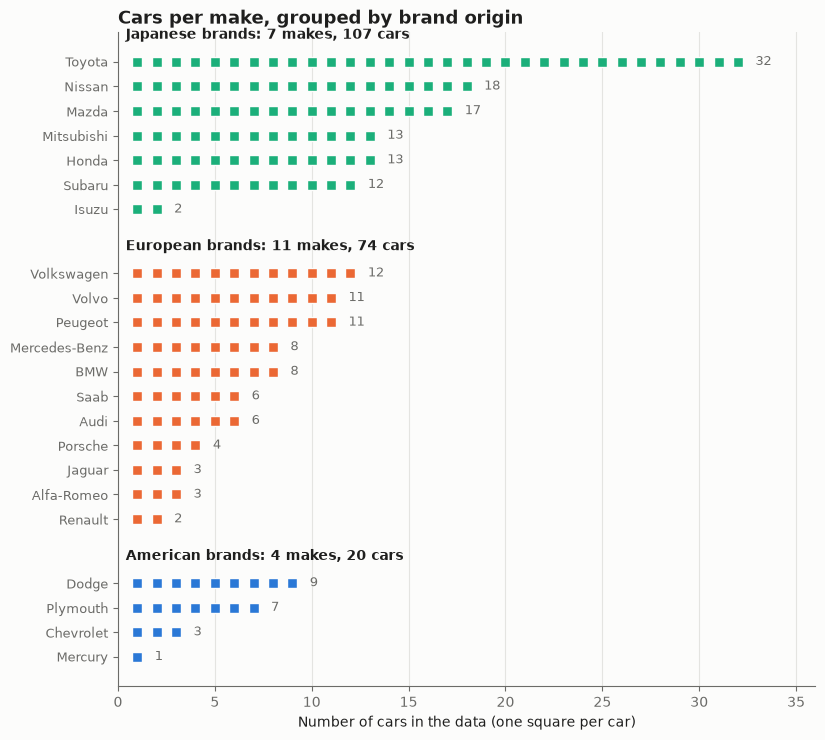

In [14]:
def plot_cars_per_make(cars: pd.DataFrame) -> None:
    """Draw one square per car, a row per make, the makes grouped by origin.

    Args:
        cars: The clean table with origin.
    """
    counts = cars.groupby(["origin", "make"]).size()
    figure, axes = plt.subplots(figsize=(9, 8.5))
    row, ticks, names = 0, [], []
    for origin in ORIGINS:
        group = counts[origin].sort_values()
        for make, total in group.items():
            axes.scatter(range(1, total + 1), [row] * total, marker="s", s=52,
                         color=ORIGIN_COLORS[origin], edgecolors=SURFACE, linewidths=1)
            axes.text(total + 0.9, row, str(total), va="center", fontsize=9, color=MUTED)
            ticks.append(row)
            names.append(make)
            row += 1
        axes.text(0.4, row - 0.2, f"{origin} brands: {len(group)} makes, {group.sum()} cars",
                  fontsize=10, fontweight="bold", va="bottom")
        row += 1.6
    axes.set_yticks(ticks, names, fontsize=9)
    axes.set_xlim(0, 36)
    axes.set_xlabel("Number of cars in the data (one square per car)")
    axes.set_title("Cars per make, grouped by brand origin", loc="left")
    axes.grid(axis="y", visible=False)
    save_and_show(figure, "q2_1_cars_per_make.png")


plot_cars_per_make(CARS)

**Summary:** To start, when looking at this data, I was thinking of what the story of this data should be. I thought it would be fun to group 'make' by region of origin to get more of a vibe of this data from a more global perspective. I thought a waffle chart would be nice compared to a bar chart because i think by showing a box to represent each car rather than just a bar helps show how many cars are really distributed by region, almost like a top down view of an organized parking lot.

### 2. What they cost

Each dot is a car, with a black tick at each make's median price. Makes are sorted from the
cheapest median at the bottom to the most expensive at the top.

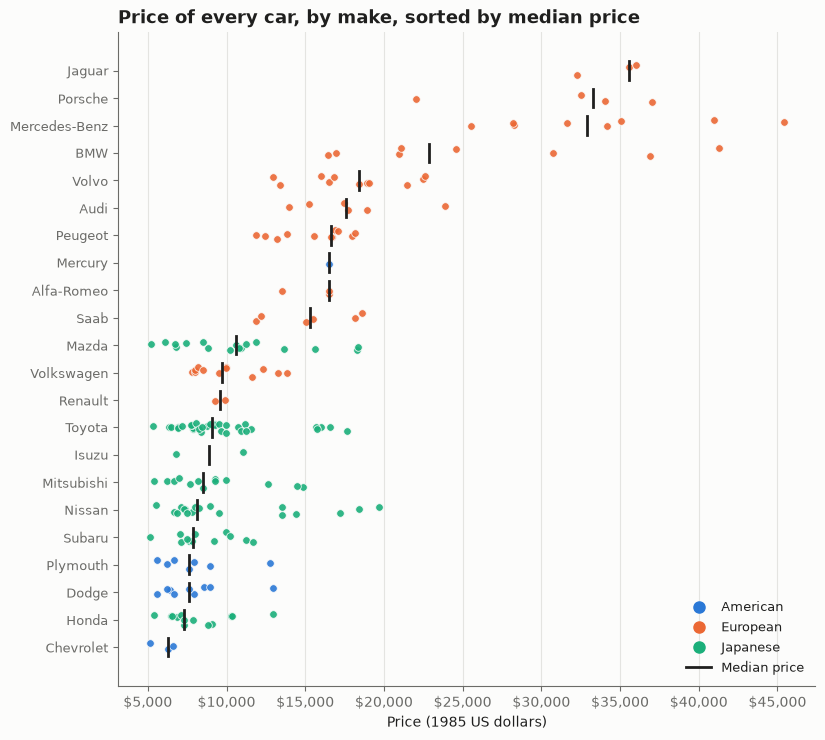

In [15]:
def plot_price_by_make(cars: pd.DataFrame) -> None:
    """Draw every car's price as a dot, one row per make, sorted by median price.

    Args:
        cars: The clean table with origin.
    """
    medians = cars.groupby("make")["price"].median().sort_values()
    figure, axes = plt.subplots(figsize=(9, 8.5))
    for position, make in enumerate(medians.index):
        group = cars[cars["make"] == make]
        spread = JITTER.uniform(-0.2, 0.2, len(group))     # nudge dots apart vertically
        axes.scatter(group["price"], position + spread, s=30, alpha=0.9,
                     color=ORIGIN_COLORS[group["origin"].iloc[0]], edgecolors=SURFACE,
                     linewidths=0.6, zorder=2)
        axes.plot([medians[make]] * 2, [position - 0.34, position + 0.34], color=TEXT_COLOR,
                  linewidth=2, zorder=3)
    axes.set_yticks(range(len(medians)), medians.index, fontsize=9)
    axes.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"${value:,.0f}"))
    axes.set_xlabel("Price (1985 US dollars)")
    axes.set_title("Price of every car, by make, sorted by median price", loc="left")
    axes.grid(axis="y", visible=False)
    median_tick = plt.Line2D([], [], color=TEXT_COLOR, linewidth=2, label="Median price")
    origin_legend(axes, [median_tick])
    save_and_show(figure, "q2_2_price_by_make.png")


plot_price_by_make(CARS)

**Summary:** I wanted to keep color consistent across all visuals so that carries down from the first one. This distribution shows how the price of make, color by region shows how these car makers price is grouped by region of origin. 

### 3. What they burn

Each dot is a car. Fuel use is shown as **gallons per 100 miles** (100 divided by mpg), with the
matching mpg in brackets: fuel use grows in a straight line with engine size, while mpg curves.
The large rings are each origin's average car.

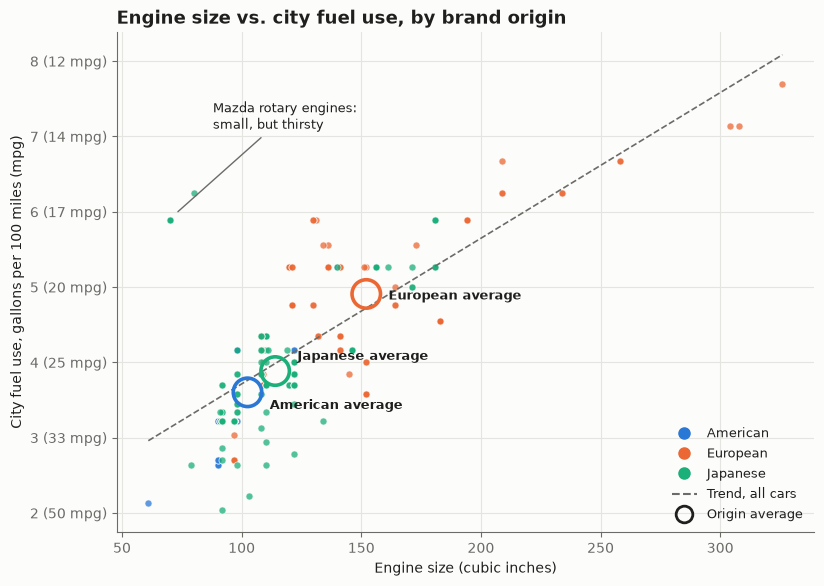

In [16]:
LABEL_NUDGE = {"American": (16, -12), "European": (16, -4), "Japanese": (16, 8)}


def plot_engine_vs_fuel_use(cars: pd.DataFrame) -> None:
    """Draw engine size against city fuel use, with each origin's average car as a ring.

    Args:
        cars: The clean table with origin.
    """
    use = 100 / cars["city_mpg"]                    # gallons per 100 miles
    figure, axes = plt.subplots(figsize=(9, 6.5))
    slope, intercept = np.polyfit(cars["engine_size"], use, 1)
    span = np.array([cars["engine_size"].min(), cars["engine_size"].max()])
    axes.plot(span, slope * span + intercept, color=MUTED, linestyle="--", linewidth=1.2,
              label="Straight-line trend, all cars")
    for origin in ORIGINS:
        mask = cars["origin"] == origin
        axes.scatter(cars.loc[mask, "engine_size"], use[mask], s=26, alpha=0.75,
                     color=ORIGIN_COLORS[origin], edgecolors=SURFACE, linewidths=0.6)
        center = (cars.loc[mask, "engine_size"].mean(), use[mask].mean())
        axes.scatter(*center, s=420, facecolors="none", edgecolors=ORIGIN_COLORS[origin],
                     linewidths=2.6, zorder=4)
        axes.annotate(f"{origin} average", center, xytext=LABEL_NUDGE[origin],
                      textcoords="offset points", fontsize=9, fontweight="bold")
    rotary = cars["engine_type"] == "rotor"
    axes.annotate("Mazda rotary engines:\nsmall, but thirsty",
                  (cars.loc[rotary, "engine_size"].mean(), use[rotary].mean()),
                  xytext=(88, 7.1), fontsize=9,
                  arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1})
    gallons = [2, 3, 4, 5, 6, 7, 8]
    axes.set_yticks(gallons, [f"{g} ({100 / g:.0f} mpg)" for g in gallons])
    axes.set_xlabel("Engine size (cubic inches)")
    axes.set_ylabel("City fuel use, gallons per 100 miles (mpg)")
    axes.set_title("Engine size vs. city fuel use, by brand origin", loc="left")
    trend = plt.Line2D([], [], color=MUTED, linestyle="--", label="Trend, all cars")
    ring = plt.Line2D([], [], marker="o", linestyle="", markersize=12, markerfacecolor="none",
                      markeredgecolor=TEXT_COLOR, markeredgewidth=2, label="Origin average")
    origin_legend(axes, [trend, ring])
    save_and_show(figure, "q2_3_engine_vs_fuel_use.png")


plot_engine_vs_fuel_use(CARS)

**Summary:** Okay, this is getting a little intersting from what we learned about how price is distributed, that while European cars are more expensive, on average, European cars also are more fuel efficient, so perhaps this is explaining why, but we would have to do statistics to know for sure.

### 4. How they make power

Each mark is a car: circles are standard engines, triangles are turbocharged. Cylinder counts
are stored as text (a deliberate choice in Question 1) and only displayed in counting order.

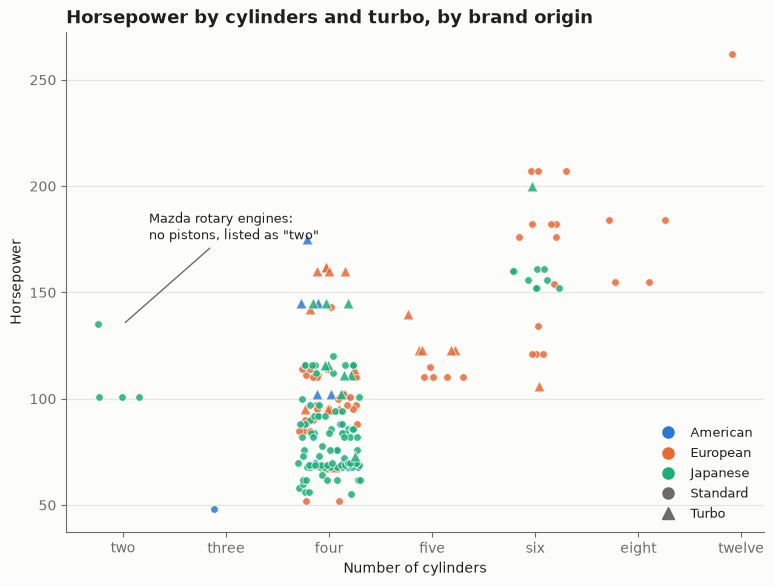

2 cars with no horsepower recorded are left out


In [17]:
def plot_horsepower_by_cylinders(cars: pd.DataFrame) -> None:
    """Draw every car's horsepower by cylinder count, shaped by aspiration, colored by origin.

    Args:
        cars: The clean table with origin.
    """
    known = cars.dropna(subset=["horsepower"])
    position = known["num_of_cylinders"].map(CYLINDER_ORDER.index)
    figure, axes = plt.subplots(figsize=(9, 6.5))
    for (origin, aspiration), group in known.groupby(["origin", "aspiration"]):
        spread = JITTER.uniform(-0.3, 0.3, len(group))      # wide: 157 cars share "four"
        axes.scatter(position[group.index] + spread, group["horsepower"],
                     marker="^" if aspiration == "turbo" else "o",
                     s=60 if aspiration == "turbo" else 30, alpha=0.85,
                     color=ORIGIN_COLORS[origin], edgecolors=SURFACE, linewidths=0.6)
    rotary = known[known["num_of_cylinders"] == "two"]["horsepower"]
    axes.annotate("Mazda rotary engines:\nno pistons, listed as \"two\"", (0, rotary.max()),
                  xytext=(0.25, 175), fontsize=9, color=TEXT_COLOR,
                  arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1})
    axes.set_xticks(range(len(CYLINDER_ORDER)), CYLINDER_ORDER)
    axes.set_xlabel("Number of cylinders")
    axes.set_ylabel("Horsepower")
    axes.set_title("Horsepower by cylinders and turbo, by brand origin", loc="left")
    axes.grid(axis="x", visible=False)
    shapes = [plt.Line2D([], [], marker=marker, linestyle="", markersize=8, color=MUTED,
                         label=label)
              for marker, label in (("o", "Standard"), ("^", "Turbo"))]
    origin_legend(axes, shapes)
    save_and_show(figure, "q2_4_horsepower_by_cylinders.png")


plot_horsepower_by_cylinders(CARS)
print(f"{CARS['horsepower'].isna().sum()} cars with no horsepower recorded are left out")

**Summary:** I think this is interesting as well, I was curious about cylinder and aspiration on horsepower, so i had to add a new way to encode that extra dimension without losing color which I already set to region of origin for this story. But this is showing that clearly most of the data is for 4 cylindar standard engines between 75ish and 115ish horespower and that anything outside that is more rare.

### 5. What the fuel type buys

For each origin, the median city mpg of its gas cars (circle) and diesel cars (diamond), joined by
a line. The numbers in brackets are how many cars each median comes from.

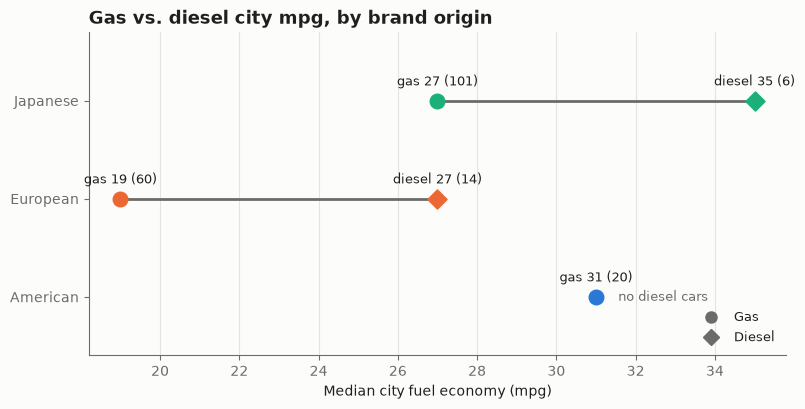

In [18]:
def plot_fuel_type_mileage(cars: pd.DataFrame) -> None:
    """Draw a dumbbell per origin: median city mpg for gas cars and for diesel cars.

    Args:
        cars: The clean table with origin.
    """
    medians = cars.groupby(["origin", "fuel_type"])["city_mpg"].median().unstack()
    counts = cars.groupby(["origin", "fuel_type"]).size().unstack(fill_value=0)
    figure, axes = plt.subplots(figsize=(9, 4.2))
    for row, origin in enumerate(ORIGINS):
        gas, diesel = medians.loc[origin, "gas"], medians.loc[origin, "diesel"]
        color = ORIGIN_COLORS[origin]
        axes.scatter(gas, row, marker="o", s=110, color=color, zorder=3)
        axes.annotate(f"gas {gas:g} ({counts.loc[origin, 'gas']})", (gas, row),
                      xytext=(0, 11), textcoords="offset points", ha="center", fontsize=9)
        if pd.isna(diesel):
            axes.annotate("no diesel cars", (gas, row), xytext=(16, -3),
                          textcoords="offset points", fontsize=9, color=MUTED)
            continue
        axes.plot([gas, diesel], [row, row], color=MUTED, linewidth=2, zorder=2)
        axes.scatter(diesel, row, marker="D", s=95, color=color, zorder=3)
        axes.annotate(f"diesel {diesel:g} ({counts.loc[origin, 'diesel']})", (diesel, row),
                      xytext=(0, 11), textcoords="offset points", ha="center", fontsize=9)
    axes.set_yticks(range(len(ORIGINS)), ORIGINS)
    axes.set_ylim(-0.6, len(ORIGINS) - 0.3)
    axes.set_xlabel("Median city fuel economy (mpg)")
    axes.set_title("Gas vs. diesel city mpg, by brand origin", loc="left")
    axes.grid(axis="y", visible=False)
    shapes = [plt.Line2D([], [], marker=marker, linestyle="", markersize=8, color=MUTED,
                         label=label) for marker, label in (("o", "Gas"), ("D", "Diesel"))]
    axes.legend(handles=shapes, loc="lower right", fontsize=9)
    save_and_show(figure, "q2_5_fuel_type_mileage.png")


plot_fuel_type_mileage(CARS)

**Summary:** In remembering the first visualization, we know that European cars are more expensive, and in general also more powerful, and now we know that also indicates that they are less fuel efficient than other regions.

## Question 3: ANOVA

> Select a null and alternative hypothesis for your data set based on what you learned in question
> 2. Perform an ANOVA. Clearly state in your own words what you know about your hypothesis from the
> ANOVA.

**From Question 2:** European cars cost the most, and they also have the most horsepower. So is
the European price premium just paying for power, or do European cars cost more for the same
power? The measure is **price per horsepower**: each car's price divided by its horsepower.

**Hypotheses** (written before any test was run):

- **H0:** mean price per horsepower is the same for American, European and Japanese brands.
- **H1:** at least one origin's mean price per horsepower is different.

**Plan:** significance level 0.05.
1. The one-way ANOVA (`f_oneway`).
2. Levene's test for whether the three origins' spreads are equal, since the ANOVA assumes they are.
3. If they aren't, Welch's ANOVA, which doesn't assume equal spreads, and Kruskal-Wallis, which compares ranks instead of means.
4. A pairwise follow-up to show *which* origins differ and in which direction, since an ANOVA only says whether at least one does.

In [19]:
# ---- Question 3: price per horsepower by origin ----
ALPHA = 0.05      # significance level, fixed before running any test


def add_price_per_horsepower(cars: pd.DataFrame) -> pd.DataFrame:
    """Add dollars_per_hp: each car's price divided by its horsepower.

    The 2 cars with no horsepower recorded can't get a value, so they are dropped here.

    Args:
        cars: The clean table with origin.

    Returns:
        A copy with dollars_per_hp, without the cars missing horsepower.
    """
    known = cars.dropna(subset=["horsepower"]).copy()
    known["dollars_per_hp"] = known["price"] / known["horsepower"].astype(float)
    return known


def groups_by_origin(frame: pd.DataFrame, column: str) -> list:
    """Split one column into a list of arrays, one per origin, in the fixed ORIGINS order.

    Args:
        frame: A table with origin.
        column: The measure to split.

    Returns:
        [American values, European values, Japanese values] as float arrays.
    """
    return [frame.loc[frame["origin"] == origin, column].to_numpy(dtype=float)
            for origin in ORIGINS]


PER_HP = add_price_per_horsepower(CARS)
print(PER_HP.groupby("origin")["dollars_per_hp"]
      .agg(["count", "mean", "median", "std"]).round(1).to_string())

          count   mean  median   std
origin                              
American     20   93.4    92.7  10.1
European     72  158.0   152.7  39.8
Japanese    107  105.9   101.4  23.4


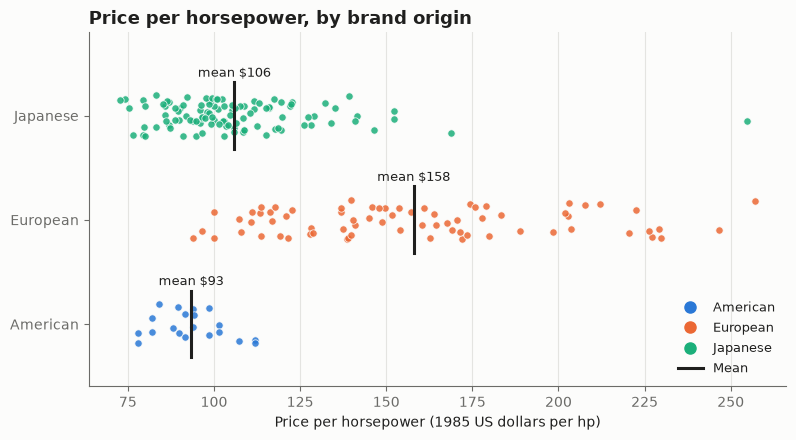

In [20]:
def plot_price_per_horsepower(frame: pd.DataFrame) -> None:
    """Draw every car's price per horsepower by origin, with each origin's mean marked.

    Args:
        frame: The table with dollars_per_hp.
    """
    figure, axes = plt.subplots(figsize=(9, 4.6))
    for row, origin in enumerate(ORIGINS):
        values = frame.loc[frame["origin"] == origin, "dollars_per_hp"]
        spread = JITTER.uniform(-0.2, 0.2, len(values))
        axes.scatter(values, row + spread, s=28, alpha=0.85, color=ORIGIN_COLORS[origin],
                     edgecolors=SURFACE, linewidths=0.6, zorder=2)
        axes.plot([values.mean()] * 2, [row - 0.32, row + 0.32], color=TEXT_COLOR, linewidth=2.2,
                  zorder=3)
        axes.annotate(f"mean ${values.mean():,.0f}", (values.mean(), row + 0.32),
                      xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    axes.set_yticks(range(len(ORIGINS)), ORIGINS)
    axes.set_ylim(-0.6, len(ORIGINS) - 0.2)
    axes.set_xlabel("Price per horsepower (1985 US dollars per hp)")
    axes.set_title("Price per horsepower, by brand origin", loc="left")
    axes.grid(axis="y", visible=False)
    mean_tick = plt.Line2D([], [], color=TEXT_COLOR, linewidth=2.2, label="Mean")
    origin_legend(axes, [mean_tick])
    save_and_show(figure, "q3_price_per_horsepower.png")


plot_price_per_horsepower(PER_HP)

In [21]:
def run_anova(groups: list) -> pd.DataFrame:
    """Run the one-way ANOVA plus the checks that decide how far to trust it.

    - f_oneway: the one-way ANOVA from class; it assumes the groups have equal spreads.
    - Levene: tests whether the groups' spreads are equal.
    - Welch's ANOVA: the same question as the ANOVA, without assuming equal spreads.
    - Kruskal-Wallis: compares ranks instead of means, so skew and outliers matter less.

    Args:
        groups: One array of values per origin.

    Returns:
        One row per test: its statistic, its p-value and whether p is below ALPHA.
    """
    results = (("One-way ANOVA (f_oneway)", stats.f_oneway(*groups)),
               ("Levene (are the spreads equal?)", stats.levene(*groups)),
               ("Welch's ANOVA", stats.f_oneway(*groups, equal_var=False)),
               ("Kruskal-Wallis", stats.kruskal(*groups)))
    return pd.DataFrame([{"test": name, "statistic": round(float(result.statistic), 3),
                          "p-value": float(result.pvalue), f"p < {ALPHA}": result.pvalue < ALPHA}
                         for name, result in results])


def format_p(p_value: float) -> str:
    """Show a p-value in scientific notation, or as "< 1e-15" when it's too small to print.

    A p-value is never exactly 0; below about 1e-15 the computer just can't represent it.

    Args:
        p_value: The p-value to show.

    Returns:
        The p-value as text.
    """
    return "< 1e-15" if p_value < 1e-15 else f"{p_value:.2e}"


def eta_squared(groups: list) -> float:
    """Measure effect size: the share of all the variation that lies between the origins' means.

    Args:
        groups: One array of values per origin.

    Returns:
        Between-group sum of squares divided by the total sum of squares (0 to 1).
    """
    values = np.concatenate(groups)
    grand_mean = values.mean()
    between = sum(len(group) * (group.mean() - grand_mean) ** 2 for group in groups)
    return float(between / ((values - grand_mean) ** 2).sum())


GROUPS = groups_by_origin(PER_HP, "dollars_per_hp")
TESTS = run_anova(GROUPS)
print(TESTS.to_string(index=False, formatters={"p-value": format_p}))
print(f"\nDegrees of freedom: {len(GROUPS) - 1} between origins, "
      f"{sum(map(len, GROUPS)) - len(GROUPS)} within")
print(f"Effect size (eta squared): {eta_squared(GROUPS):.3f}")

                           test  statistic  p-value  p < 0.05
       One-way ANOVA (f_oneway)     77.932  < 1e-15      True
Levene (are the spreads equal?)     21.136 4.87e-09      True
                  Welch's ANOVA     76.460  < 1e-15      True
                 Kruskal-Wallis     96.086  < 1e-15      True

Degrees of freedom: 2 between origins, 196 within
Effect size (eta squared): 0.443


In [22]:
def pairwise_comparisons(groups: list, equal_spreads: bool) -> pd.DataFrame:
    """Compare every pair of origins, with a method that matches Levene's verdict.

    With equal spreads this is Tukey's HSD. Without them, scipy's tukey_hsd(equal_var=False)
    runs Games-Howell, the version of Tukey's test that doesn't assume equal spreads.

    Args:
        groups: One array of values per origin, in ORIGINS order.
        equal_spreads: Whether Levene's test found the spreads equal.

    Returns:
        One row per pair: the difference in means (first minus second), its 95% interval
        and its p-value.
    """
    result = stats.tukey_hsd(*groups, equal_var=equal_spreads)
    interval = result.confidence_interval(confidence_level=0.95)
    rows = []
    for first, second in ((1, 0), (1, 2), (2, 0)):
        rows.append({"pair": f"{ORIGINS[first]} minus {ORIGINS[second]}",
                     "mean difference": round(float(result.statistic[first, second]), 1),
                     "95% interval": (f"{interval.low[first, second]:.1f} to "
                                      f"{interval.high[first, second]:.1f}"),
                     "p-value": float(result.pvalue[first, second])})
    return pd.DataFrame(rows)


EQUAL_SPREADS = bool(TESTS.loc[TESTS["test"].str.startswith("Levene"), "p-value"].iloc[0]
                     >= ALPHA)
print("Method:", "Tukey's HSD" if EQUAL_SPREADS
      else "Games-Howell (Tukey's HSD without the equal-spread assumption)")
print(pairwise_comparisons(GROUPS, EQUAL_SPREADS)
      .to_string(index=False, formatters={"p-value": format_p}))

Method: Games-Howell (Tukey's HSD without the equal-spread assumption)
                   pair  mean difference 95% interval  p-value
European minus American             64.6 52.2 to 77.0  < 1e-15
European minus Japanese             52.1 39.7 to 64.4 2.89e-15
Japanese minus American             12.5  4.9 to 20.2 6.25e-04


**Conclusion:** European cars are on average more expensive and on average have more horsepower, so first we needed a fair comparison using price per horsepower. Then the question becomes: are European cars more expensive because they have more horsepower? If yes, then every region should charge about the same for each horsepower, but we see that this is not the case. The ANOVA rejects the null hypothesis: average price per horsepower is not the same across American, European and Japanese brands, and the gap is far too big to be chance (p < 1e-15, and the tests that don't assume equal spreads agree). There is actually a $50–65 per horsepower European premium over both Japanese and American brands that power alone doesn't explain; it could be that these are luxury cars and have other luxury features which explain this. So European cars are not more expensive just because they were more powerful.